In [14]:
import numpy as np 
import pandas as pd 
from scipy.optimize import minimize

## 2 Mean-Variance Optimization

In [15]:
# 0. Read the data

prices = pd.read_excel('multi_asset_etf_data.xlsx', sheet_name='prices')
total_returns = pd.read_excel('multi_asset_etf_data.xlsx', sheet_name='total returns')
excess_returns = pd.read_excel('multi_asset_etf_data.xlsx', sheet_name='excess returns')


print("Excess returns columns:", excess_returns.columns.tolist())

Excess returns columns: ['Date', 'BWX', 'DBC', 'EEM', 'EFA', 'HYG', 'IEF', 'IYR', 'PSP', 'QAI', 'SPY', 'TIP']


In [16]:
# 1. Data cleaning: drop QAI

df = excess_returns.copy()

if 'Date' in df.columns:
    df = df.set_index('Date')

if 'QAI' in df.columns:
    df = df.drop(columns=['QAI'])

if 'SHV' in df.columns:
    df = df.drop(columns=['SHV'])

print("\nAssets used:", df.columns.tolist())
print("Number of assets:", df.shape[1])


Assets used: ['BWX', 'DBC', 'EEM', 'EFA', 'HYG', 'IEF', 'IYR', 'PSP', 'SPY', 'TIP']
Number of assets: 10


In [17]:
# 2. Summary statistics (annualized)

ann_factor_mean = 12
ann_factor_vol = np.sqrt(12)

mu_monthly = df.mean()               # Monthly mean excess return
vol_monthly = df.std(ddof=1)         # Monthly volatility (sample std)

mu_annual = mu_monthly * ann_factor_mean
vol_annual = vol_monthly * ann_factor_vol
sharpe_annual = mu_annual / vol_annual

summary = pd.DataFrame({
    'Mean (Annualized)': mu_annual,
    'Vol (Annualized)': vol_annual,
    'Sharpe (Annualized)': sharpe_annual
}).sort_values('Sharpe (Annualized)', ascending=False)

print("\n=====  Summary Statistics (Annualized) =====")
print(summary)

best = summary.index[0]
worst = summary.index[-1]
print(f"\nBest Sharpe: {best} ({summary.loc[best, 'Sharpe (Annualized)']:.4f})")
print(f"Worst Sharpe: {worst} ({summary.loc[worst, 'Sharpe (Annualized)']:.4f})")


=====  Summary Statistics (Annualized) =====
     Mean (Annualized)  Vol (Annualized)  Sharpe (Annualized)
SPY           0.126955          0.141398             0.897856
HYG           0.034500          0.073326             0.470501
EFA           0.063754          0.148590             0.429057
IYR           0.070095          0.165531             0.423456
PSP           0.076428          0.211323             0.361666
TIP           0.012776          0.049748             0.256817
EEM           0.044426          0.179085             0.248074
IEF           0.008596          0.062120             0.138377
DBC           0.013000          0.172276             0.075461
BWX          -0.017163          0.081891            -0.209582

Best Sharpe: SPY (0.8979)
Worst Sharpe: BWX (-0.2096)


In [21]:
# 3. Correlation matrix

corr = df.corr()

print("\n===== 2. Correlation Matrix =====")
print(corr.round(3))

# Find the highest / lowest correlated pairs
corr_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
corr_stacked = corr_pairs.stack().sort_values(ascending=False)

highest_pair = corr_stacked.index[0]
lowest_pair = corr_stacked.index[-1]
print(f"\nHighest correlation pair: {highest_pair} = {corr_stacked.iloc[0]:.4f}")
print(f"Lowest correlation pair:  {lowest_pair} = {corr_stacked.iloc[-1]:.4f}")

# TIP performance
if 'TIP' in df.columns:
    print("\n--- TIP performance vs Domestic/Foreign Bonds ---")
    for a in df.columns:
        if a != 'TIP':
            print(f"TIP Sharpe {sharpe_annual['TIP']:.4f} vs {a}: {sharpe_annual[a]:.4f}")


===== 2. Correlation Matrix =====
       BWX    DBC    EEM    EFA    HYG    IEF    IYR    PSP    SPY    TIP
BWX  1.000  0.161  0.612  0.613  0.600  0.581  0.555  0.524  0.444  0.675
DBC  0.161  1.000  0.439  0.440  0.419 -0.309  0.253  0.420  0.384  0.084
EEM  0.612  0.439  1.000  0.812  0.670  0.051  0.574  0.697  0.693  0.384
EFA  0.613  0.440  0.812  1.000  0.776  0.063  0.700  0.862  0.833  0.402
HYG  0.600  0.419  0.670  0.776  1.000  0.193  0.731  0.798  0.783  0.540
IEF  0.581 -0.309  0.051  0.063  0.193  1.000  0.322  0.012  0.011  0.756
IYR  0.555  0.253  0.574  0.700  0.731  0.322  1.000  0.726  0.743  0.600
PSP  0.524  0.420  0.697  0.862  0.798  0.012  0.726  1.000  0.872  0.397
SPY  0.444  0.384  0.693  0.833  0.783  0.011  0.743  0.872  1.000  0.386
TIP  0.675  0.084  0.384  0.402  0.540  0.756  0.600  0.397  0.386  1.000

Highest correlation pair: ('PSP', 'SPY') = 0.8722
Lowest correlation pair:  ('DBC', 'IEF') = -0.3088

--- TIP performance vs Domestic/Foreign Bonds --

In [24]:
# 4. Tangency portfolio

# Use sample means and sample covariance matrix
mu_vec = mu_monthly.values                  # Monthly means
Sigma = df.cov().values                     # Monthly covariance

def tangency_weights(mu, Sigma):
    """Compute tangency weights w ∝ Σ^{-1} μ, normalized to sum to 1."""
    inv_Sigma = np.linalg.inv(Sigma)
    raw = inv_Sigma @ mu
    w = raw / raw.sum()
    return w

w_tan = tangency_weights(mu_vec, Sigma)
assets = df.columns.tolist()
w_series = pd.Series(w_tan, index=assets)

print("\n===== Tangency Portfolio Weights =====")
print(w_series.sort_values(ascending=False))

# Tangency portfolio performance
port_mu_monthly = w_series.values @ mu_vec
port_var_monthly = w_series.values @ Sigma @ w_series.values
port_vol_monthly = np.sqrt(port_var_monthly)

port_mu_annual = port_mu_monthly * 12
port_vol_annual = port_vol_monthly * np.sqrt(12)
port_sharpe_annual = port_mu_annual / port_vol_annual

print(f"\nTangency Portfolio (annualized):")
print(f"  Mean:   {port_mu_annual:.4f}")
print(f"  Vol:    {port_vol_annual:.4f}")
print(f"  Sharpe: {port_sharpe_annual:.4f}")

# Compare weight ranking vs Sharpe ranking
rank_weights = w_series.rank(ascending=False)
rank_sharpe = sharpe_annual.reindex(assets).rank(ascending=False)
rank_compare = pd.DataFrame({
    'Weight': w_series,
    'Weight Rank': rank_weights,
    'Sharpe': sharpe_annual.reindex(assets),
    'Sharpe Rank': rank_sharpe
}).sort_values('Weight Rank')


===== Tangency Portfolio Weights =====
IEF    1.318799
SPY    1.263152
HYG    0.203791
EFA    0.184843
DBC    0.036303
EEM   -0.000976
TIP   -0.191988
IYR   -0.223668
PSP   -0.410585
BWX   -1.179671
dtype: float64

Tangency Portfolio (annualized):
  Mean:   0.1617
  Vol:    0.1096
  Sharpe: 1.4758


In [ ]:
print("\n--- Weight ranking vs Sharpe ranking ---")
print(rank_compare.round(4))


--- Weight ranking vs Sharpe ranking ---
     Weight  Weight Rank  Sharpe  Sharpe Rank
IEF  1.3188          1.0  0.1384          8.0
SPY  1.2632          2.0  0.8979          1.0
HYG  0.2038          3.0  0.4705          2.0
EFA  0.1848          4.0  0.4291          3.0
DBC  0.0363          5.0  0.0755          9.0
EEM -0.0010          6.0  0.2481          7.0
TIP -0.1920          7.0  0.2568          6.0
IYR -0.2237          8.0  0.4235          4.0
PSP -0.4106          9.0  0.3617          5.0
BWX -1.1797         10.0 -0.2096         10.0


In [26]:
# ============================================================
# 5. TIP analysis
# ============================================================
def portfolio_stats(weights, mu_vec, Sigma):
    w = np.asarray(weights)
    m = w @ mu_vec * 12
    v = np.sqrt(w @ Sigma @ w) * np.sqrt(12)
    s = m / v
    return m, v, s

# (a) Drop TIP entirely
if 'TIP' in df.columns:
    df_no_tip = df.drop(columns=['TIP'])
    mu_no_tip = df_no_tip.mean().values
    Sigma_no_tip = df_no_tip.cov().values
    w_no_tip = tangency_weights(mu_no_tip, Sigma_no_tip)
    w_no_tip_s = pd.Series(w_no_tip, index=df_no_tip.columns)
    m2, v2, s2 = portfolio_stats(w_no_tip, mu_no_tip, Sigma_no_tip)

    print("\n===== 4a. Tangency Portfolio WITHOUT TIP =====")
    print(w_no_tip_s.sort_values(ascending=False))
    print(f"  Mean:   {m2:.4f}")
    print(f"  Vol:    {v2:.4f}")
    print(f"  Sharpe: {s2:.4f}")
    print(f"  Change in Sharpe vs full: {s2 - port_sharpe_annual:+.4f}")

    # (b) TIP expected excess return +0.0012 (monthly)
    mu_adj = mu_monthly.copy()
    mu_adj['TIP'] = mu_adj['TIP'] + 0.0012
    w_adj = tangency_weights(mu_adj.values, Sigma)
    w_adj_s = pd.Series(w_adj, index=assets)
    m3, v3, s3 = portfolio_stats(w_adj, mu_adj.values, Sigma)

    print("\n===== 4b. Tangency Portfolio with TIP mean +0.0012 =====")
    print(w_adj_s.sort_values(ascending=False))
    print(f"  Mean:   {m3:.4f}")
    print(f"  Vol:    {v3:.4f}")
    print(f"  Sharpe: {s3:.4f}")
    print(f"  Change in Sharpe vs full: {s3 - port_sharpe_annual:+.4f}")

    # TIP weight changes
    print("\n--- TIP weight changes ---")
    print(f"  Baseline TIP weight:       {w_series['TIP']:.4f}")
    print(f"  No-TIP weight:             0.0000")
    print(f"  Adjusted-mean TIP weight:  {w_adj_s['TIP']:.4f}")


===== 4a. Tangency Portfolio WITHOUT TIP =====
SPY    1.212796
IEF    1.161647
EFA    0.188083
HYG    0.179146
DBC    0.025790
EEM   -0.006158
IYR   -0.223391
PSP   -0.400438
BWX   -1.137476
dtype: float64
  Mean:   0.1554
  Vol:    0.1054
  Sharpe: 1.4745
  Change in Sharpe vs full: -0.0012

===== 4b. Tangency Portfolio with TIP mean +0.0012 =====
TIP    1.261685
SPY    0.881874
EFA    0.209378
IEF    0.128894
HYG    0.017187
EEM   -0.040213
DBC   -0.043295
IYR   -0.221571
PSP   -0.333754
BWX   -0.860184
dtype: float64
  Mean:   0.1327
  Vol:    0.0842
  Sharpe: 1.5749
  Change in Sharpe vs full: +0.0991

--- TIP weight changes ---
  Baseline TIP weight:       -0.1920
  No-TIP weight:             0.0000
  Adjusted-mean TIP weight:  1.2617


## 3. Allocations


===== 3A. Equally-Weighted (EW) Portfolio =====
Raw EW weights (1/n):
BWX    0.2769
DBC    0.2769
EEM    0.2769
EFA    0.2769
HYG    0.2769
IEF    0.2769
IYR    0.2769
PSP    0.2769
SPY    0.2769
TIP    0.2769
dtype: float64
Sum of weights: 2.7690
Target mean check (monthly): 0.010000
Annualized Mean:   0.1200
Annualized Vol:    0.2753
Annualized Sharpe: 0.4359

===== 3B. Risk-Parity (RP) Portfolio =====
Raw RP weights (normalized to sum to 1):
BWX    0.1225
DBC    0.0277
EEM    0.0256
EFA    0.0372
HYG    0.1528
IEF    0.2129
IYR    0.0300
PSP    0.0184
SPY    0.0411
TIP    0.3319
dtype: float64
Rescaled RP weights (target mean = 0.01):
BWX    0.6733
DBC    0.1521
EEM    0.1408
EFA    0.2045
HYG    0.8397
IEF    1.1700
IYR    0.1648
PSP    0.1011
SPY    0.2258
TIP    1.8244
dtype: float64
Sum of weights: 5.4966
Target mean check (monthly): 0.010000
Annualized Mean:   0.1200
Annualized Vol:    0.3261
Annualized Sharpe: 0.3679

===== 3C. Mean-Variance (MV) Portfolio =====
Rescaled MV w

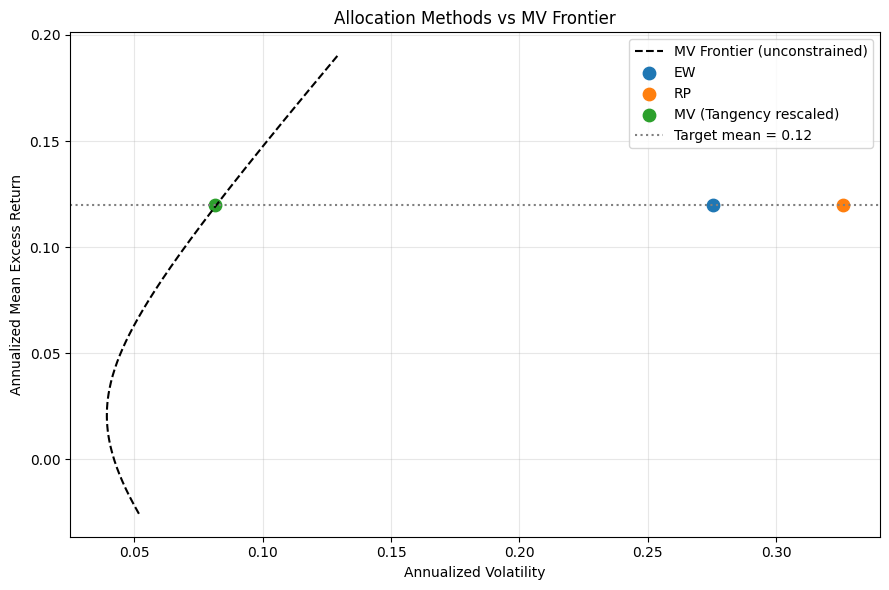

In [27]:
# Continue with the same data file as the previous section.
# Suppose the investor has a target mean excess return (per month)
# of mu_port = 0.01.

MU_PORT = 0.01   # target monthly mean excess return


def rescale_to_target(w_raw, mu_vec, target=MU_PORT):
    """
    Rescale the weight vector w_raw so that w @ mu = target.
    Note: this does NOT keep weights summing to 1; it scales the
    whole vector by a constant k = target / (w_raw @ mu).
    """
    w_raw = np.asarray(w_raw, dtype=float)
    current_mean = w_raw @ mu_vec
    k = target / current_mean
    return w_raw * k


def portfolio_performance(w, mu_vec, Sigma):
    """
    Given a weight vector w (not necessarily summing to 1), the
    monthly mean excess return vector mu_vec, and the monthly
    covariance matrix Sigma, return annualized (mean, vol, Sharpe).
    """
    w = np.asarray(w, dtype=float)
    m_monthly = w @ mu_vec
    v_monthly = np.sqrt(w @ Sigma @ w)
    m_annual = m_monthly * 12
    v_annual = v_monthly * np.sqrt(12)
    sharpe = m_annual / v_annual
    return m_annual, v_annual, sharpe

# ------------------------------------------------------------
# (A) Equally-weighted (EW)
# ------------------------------------------------------------
n = len(assets)
w_ew_raw = np.ones(n) / n

# Rescale so that w @ mu = MU_PORT
w_ew = rescale_to_target(w_ew_raw, mu_vec, MU_PORT)
w_ew_s = pd.Series(w_ew, index=assets)

m_ew, v_ew, s_ew = portfolio_performance(w_ew, mu_vec, Sigma)

print("\n===== 3A. Equally-Weighted (EW) Portfolio =====")
print("Raw EW weights (1/n):")
print(w_ew_s.round(4))
print(f"Sum of weights: {w_ew.sum():.4f}")
print(f"Target mean check (monthly): {w_ew @ mu_vec:.6f}")
print(f"Annualized Mean:   {m_ew:.4f}")
print(f"Annualized Vol:    {v_ew:.4f}")
print(f"Annualized Sharpe: {s_ew:.4f}")

# ------------------------------------------------------------
# (B) Risk-parity (RP)
# ------------------------------------------------------------
# w_i ∝ 1 / sigma_i^2, then normalize so weights sum to 1,
# then rescale so that w @ mu = MU_PORT.
var_i = np.diag(Sigma)                    # monthly variances
inv_var = 1.0 / var_i
w_rp_raw = inv_var / inv_var.sum()        # normalized to sum to 1

# Rescale to target mean
w_rp = rescale_to_target(w_rp_raw, mu_vec, MU_PORT)
w_rp_s = pd.Series(w_rp, index=assets)

m_rp, v_rp, s_rp = portfolio_performance(w_rp, mu_vec, Sigma)

print("\n===== 3B. Risk-Parity (RP) Portfolio =====")
print("Raw RP weights (normalized to sum to 1):")
print(pd.Series(w_rp_raw, index=assets).round(4))
print("Rescaled RP weights (target mean = 0.01):")
print(w_rp_s.round(4))
print(f"Sum of weights: {w_rp.sum():.4f}")
print(f"Target mean check (monthly): {w_rp @ mu_vec:.6f}")
print(f"Annualized Mean:   {m_rp:.4f}")
print(f"Annualized Vol:    {v_rp:.4f}")
print(f"Annualized Sharpe: {s_rp:.4f}")

# ------------------------------------------------------------
# (C) Mean-Variance (MV) / Tangency portfolio
# ------------------------------------------------------------
# Tangency weights w ∝ Sigma^{-1} mu, already computed in Section 3
# as w_tan. Rescale to target mean MU_PORT.
w_mv = rescale_to_target(w_tan, mu_vec, MU_PORT)
w_mv_s = pd.Series(w_mv, index=assets)

m_mv, v_mv, s_mv = portfolio_performance(w_mv, mu_vec, Sigma)

print("\n===== 3C. Mean-Variance (MV) Portfolio =====")
print("Rescaled MV weights (target mean = 0.01):")
print(w_mv_s.round(4))
print(f"Sum of weights: {w_mv.sum():.4f}")
print(f"Target mean check (monthly): {w_mv @ mu_vec:.6f}")
print(f"Annualized Mean:   {m_mv:.4f}")
print(f"Annualized Vol:    {v_mv:.4f}")
print(f"Annualized Sharpe: {s_mv:.4f}")

# ------------------------------------------------------------
# (D) Compare all three allocation methods
# ------------------------------------------------------------
comparison = pd.DataFrame({
    'EW': {'Mean': m_ew, 'Vol': v_ew, 'Sharpe': s_ew},
    'RP': {'Mean': m_rp, 'Vol': v_rp, 'Sharpe': s_rp},
    'MV': {'Mean': m_mv, 'Vol': v_mv, 'Sharpe': s_mv},
}).T

print("\n===== 3D. Comparison of Allocation Methods =====")
print(comparison.round(4))

# Rank by Sharpe
print("\nRanked by Sharpe ratio (best to worst):")
print(comparison['Sharpe'].sort_values(ascending=False).round(4))

# ------------------------------------------------------------
# (E) Visualize the three portfolios on the MV frontier
# ------------------------------------------------------------
import matplotlib.pyplot as plt

# Build the unconstrained MV frontier (excess returns, monthly)
# Frontier: for a grid of target means, find min-variance weights
targets = np.linspace(mu_vec.min() * 1.5, mu_vec.max() * 1.5, 200)
frontier_vols = []
frontier_means = []

inv_Sigma = np.linalg.inv(Sigma)
ones = np.ones(n)

# Analytical solution to min-variance with target mean:
# w = Sigma^{-1} (lambda1 * mu + lambda2 * 1)
# Solve for lambda1, lambda2 from the two constraints.
A = mu_vec @ inv_Sigma @ mu_vec
B = mu_vec @ inv_Sigma @ ones
C = ones @ inv_Sigma @ ones
D = A * C - B ** 2

for t in targets:
    lam1 = (C * t - B) / D
    lam2 = (A - B * t) / D
    w_t = inv_Sigma @ (lam1 * mu_vec + lam2 * ones)
    frontier_means.append(t * 12)
    frontier_vols.append(np.sqrt(w_t @ Sigma @ w_t) * np.sqrt(12))

plt.figure(figsize=(9, 6))
plt.plot(frontier_vols, frontier_means, 'k--', label='MV Frontier (unconstrained)')
plt.scatter([v_ew], [m_ew], color='tab:blue', s=80, label='EW')
plt.scatter([v_rp], [m_rp], color='tab:orange', s=80, label='RP')
plt.scatter([v_mv], [m_mv], color='tab:green', s=80, label='MV (Tangency rescaled)')
plt.axhline(MU_PORT * 12, color='gray', linestyle=':', label=f'Target mean = {MU_PORT*12:.2f}')
plt.xlabel('Annualized Volatility')
plt.ylabel('Annualized Mean Excess Return')
plt.title('Allocation Methods vs MV Frontier')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()